In [1]:
import sys
from pathlib import Path
sys.path.append("..")
from src.load_data import download_data, load_data

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
download_data()
df = load_data()

# "One dime" and "One quarter" are coins used as a control in the survey, not candies
df = df[~df["competitorname"].isin(["One dime", "One quarter"])].reset_index(drop=True)
df.head()

,competitorname,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
0,100 Grand,1,0,1,0,0,1,0,1,0,0.732,0.860,66.971725
1,3 Musketeers,1,0,0,0,1,0,0,1,0,0.604,0.511,67.602936
2,Air Heads,0,1,0,0,0,0,0,0,0,0.906,0.511,52.341465
3,Almond Joy,1,0,0,1,0,0,0,1,0,0.465,0.767,50.347546
4,Baby Ruth,1,0,1,1,1,0,0,1,0,0.604,0.767,56.914547


In [3]:
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

BINARY = ["chocolate", "fruity", "caramel", "peanutyalmondy",
          "nougat", "crispedricewafer", "hard", "bar", "pluribus"]
CONTINUOUS = ["sugarpercent", "pricepercent"]
TARGET = "winpercent"

df.describe().T

,count,mean,std,min,25%,50%,75%,max
chocolate,83.0,0.445783,0.500073,0.000000,0.00000,0.000000,1.000000,1.00000
fruity,83.0,0.457831,0.501247,0.000000,0.00000,0.000000,1.000000,1.00000
caramel,83.0,0.168675,0.376741,0.000000,0.00000,0.000000,0.000000,1.00000
peanutyalmondy,83.0,0.168675,0.376741,0.000000,0.00000,0.000000,0.000000,1.00000
nougat,83.0,0.084337,0.279582,0.000000,0.00000,0.000000,0.000000,1.00000
crispedricewafer,83.0,0.084337,0.279582,0.000000,0.00000,0.000000,0.000000,1.00000
hard,83.0,0.180723,0.387128,0.000000,0.00000,0.000000,0.000000,1.00000
bar,83.0,0.253012,0.437381,0.000000,0.00000,0.000000,0.500000,1.00000
pluribus,83.0,0.530120,0.502126,0.000000,0.00000,1.000000,1.000000,1.00000
sugarpercent,83.0,0.489916,0.276498,0.034000,0.26700,0.465000,0.732000,0.98800


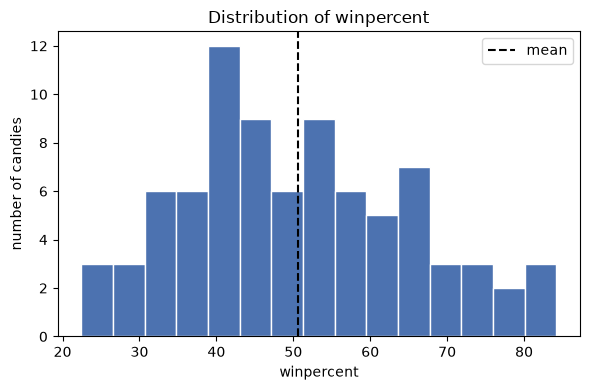

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df[TARGET], bins=15, color="#4C72B0", edgecolor="white")
ax.axvline(df[TARGET].mean(), color="black", ls="--", label="mean")
ax.set_xlabel("winpercent")
ax.set_ylabel("number of candies")
ax.set_title("Distribution of winpercent")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_winpercent_hist.png", dpi=150)
plt.show()

In [5]:
ranked = df.sort_values(TARGET, ascending=False)[["competitorname", TARGET]]
pd.concat([ranked.head(5), ranked.tail(5)])

,competitorname,winpercent
50,Reese's Peanut Butter cup,84.180290
49,Reese's Miniatures,81.866257
77,Twix,81.642914
26,Kit Kat,76.768600
62,Snickers,76.673782
24,Jawbusters,28.127439
70,Super Bubble,27.303865
10,Chiclets,24.524988
5,Boston Baked Beans,23.417824
42,Nik L Nip,22.445341


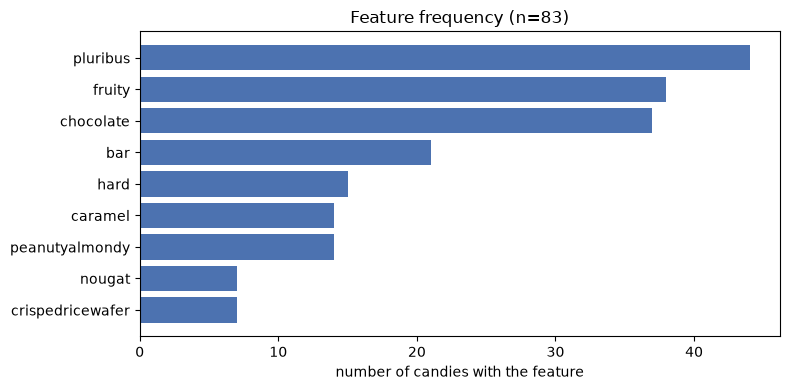

In [18]:
counts = df[BINARY].sum().sort_values()
 
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index, counts.values, color="#4C72B0")
ax.set_xlabel("number of candies with the feature")
ax.set_title(f"Feature frequency (n={len(df)})")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_feature_counts.png", dpi=150)
plt.show()

In [7]:
rows = []
for col in BINARY:
    with_feature = df.loc[df[col] == 1, TARGET]
    without_feature = df.loc[df[col] == 0, TARGET]
    rows.append((col, len(with_feature), with_feature.mean(), without_feature.mean()))

means = pd.DataFrame(rows, columns=["feature", "n_with", "with", "without"]).set_index("feature")
means = means.sort_values("with")
means

,n_with,with,without
feature,,,
hard,15,40.508982,52.807538
fruity,38,44.119741,56.044381
pluribus,44,46.822781,54.829358
caramel,14,57.346908,49.212908
nougat,7,60.051879,49.712950
chocolate,37,60.921529,42.270668
bar,21,61.295413,46.957156
peanutyalmondy,14,63.697137,47.924455
crispedricewafer,7,66.170252,49.149415


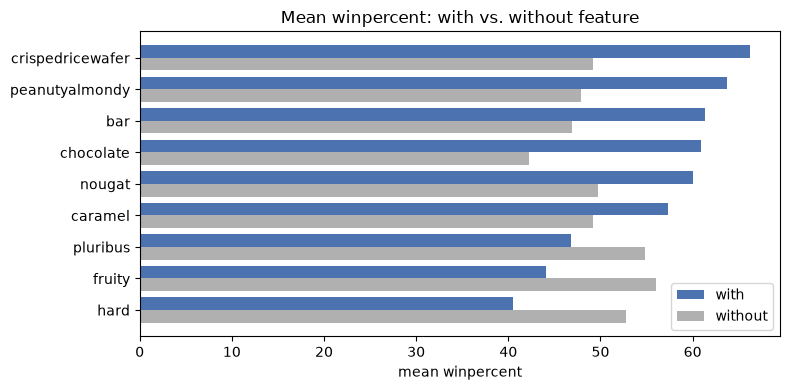

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
y = range(len(means))
ax.barh([i + 0.2 for i in y], means["with"], height=0.4, label="with", color="#4C72B0")
ax.barh([i - 0.2 for i in y], means["without"], height=0.4, label="without", color="#B0B0B0")
ax.set_yticks(list(y))
ax.set_yticklabels(means.index)
ax.set_xlabel("mean winpercent")
ax.set_title("Mean winpercent: with vs. without feature")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_mean_win_by_feature.png", dpi=150)
plt.show()

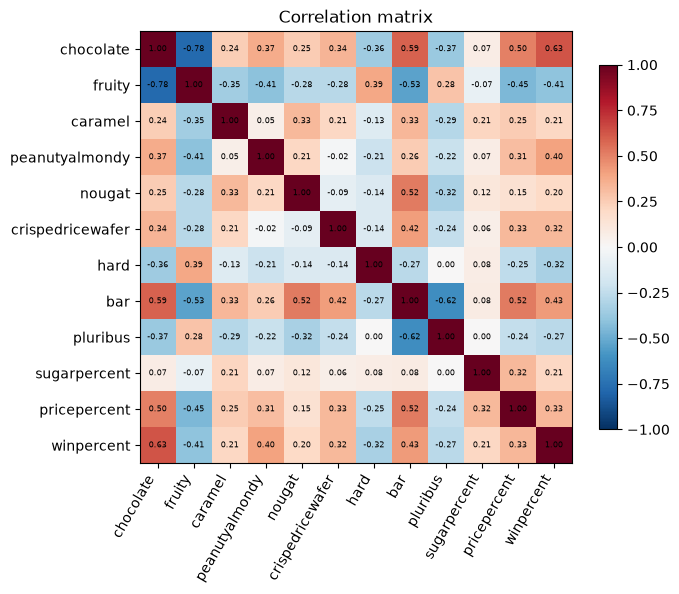

In [9]:
cols = BINARY + CONTINUOUS + [TARGET]
corr = df[cols].corr()
 
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=60, ha="right")
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_corr_heatmap.png", dpi=150)
plt.show()

In [10]:
# chocolate and fruity are strongly negatively correlated
# they almost never appear together, so the data cannot tell us much about a chocolate-fruit candy
pd.crosstab(df["chocolate"], df["fruity"])

fruity,0,1
chocolate,,
0,9,37
1,36,1


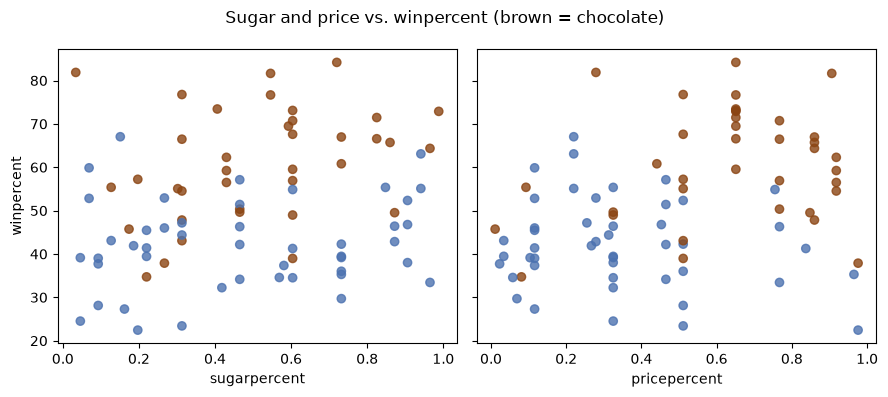

In [11]:
colors = df["chocolate"].map({1: "#8B4513", 0: "#4C72B0"})
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, col in zip(axes, CONTINUOUS):
    ax.scatter(df[col], df[TARGET], c=colors, alpha=0.8)
    ax.set_xlabel(col)
axes[0].set_ylabel("winpercent")
fig.suptitle("Sugar and price vs. winpercent (brown = chocolate)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_sugar_price_scatter.png", dpi=150)
plt.show()

## Segments: gummies vs. cookie-based

The dataset has no gummy column, so gummies are labelled by hand from `competitorname` (broad definition: anything with a gummy texture, gelatin- or starch-based).

- **Certain gummies:** Haribo Gold Bears, Haribo Happy Cola, Haribo Sour Bears, Haribo Twin Snakes, Lifesavers big ring gummies, Welch's Fruit Snacks, Sour Patch Tricksters.
- **Borderline, included:** Sour Patch Kids, Swedish Fish (starch-based, sold as "soft & chewy"), Trolli Sour Bites (gummy with a sugar shell), Dots (gumdrops).
- **Not gummies, although they look similar:**
  - chewy candies: Mike & Ike, Starburst, Skittles, Laffy Taffy
  - licorice: Twizzlers, Red vines
  - wax bottle: Nik L Nip
  - gum: Chiclets

"Cookie-based" uses the dataset's own `crispedricewafer` column ("crisped rice, wafers, or a cookie component"). Only Twix is a cookie in the strict sense, so this is a broader "crunchy" group.

Both segments are small (n = 11 and n = 7), so any difference is indicative only.

In [12]:
gummies = [
    "Haribo Gold Bears", "Haribo Happy Cola", "Haribo Sour Bears",
    "Haribo Twin Snakes", "Lifesavers big ring gummies", "Welch's Fruit Snacks",
    "Sour Patch Tricksters", "Sour Patch Kids", "Swedish Fish",
    "Trolli Sour Bites", "Dots",
]
df["gummy"] = df["competitorname"].isin(gummies).astype(int)

segments = {
    "gummy": df["gummy"] == 1,
    "cookie-based": df["crispedricewafer"] == 1,
}

summary = []
for name, mask in segments.items():
    summary.append((name, mask.sum(), df.loc[mask, TARGET].mean(), df.loc[mask, TARGET].std()))
pd.DataFrame(summary, columns=["segment", "n", "mean_winpercent", "std"]).round(1)

,segment,n,mean_winpercent,std
0,gummy,11,49.0,7.7
1,cookie-based,7,66.2,10.7


In [13]:
# the two segments do not overlap
pd.crosstab(df["crispedricewafer"], df["gummy"])

gummy,0,1
crispedricewafer,,
0,65,11
1,7,0


In [14]:
pd.crosstab([df["crispedricewafer"], df["gummy"]], df["chocolate"])

chocolate                0   1
crispedricewafer gummy        
0                0      35  30
                 1      11   0
1                0       0   7

In [15]:
for name, mask in segments.items():
    print(name, ":", ", ".join(df.loc[mask, "competitorname"]))
 

gummy : Dots, Haribo Gold Bears, Haribo Happy Cola, Haribo Sour Bears, Haribo Twin Snakes, Lifesavers big ring gummies, Sour Patch Kids, Sour Patch Tricksters, Swedish Fish, Trolli Sour Bites, Welch's Fruit Snacks
cookie-based : 100 Grand, Hershey's Krackel, Kit Kat, Nestle Crunch, Snickers Crisper, Twix, Whoppers


## Controlling for chocolate

Every cookie-based candy contains chocolate, and no gummy does. A direct gummy vs. cookie-based comparison therefore mostly measures the chocolate effect. Each segment is compared with its natural peers instead: cookie-based with the other chocolate candies, and gummies with the other non-chocolate candies.

In [16]:
choc = df["chocolate"] == 1
cookie = df["crispedricewafer"] == 1
gummy = df["gummy"] == 1

groups = {
    "cookie-based": choc & cookie,
    "other chocolate": choc & ~cookie,
    "gummy": ~choc & gummy,
    "other non-chocolate": ~choc & ~gummy,
}

rows = [(name, mask.sum(), df.loc[mask, TARGET].mean()) for name, mask in groups.items()]
pd.DataFrame(rows, columns=["group", "n", "mean_winpercent"]).round(1)

,group,n,mean_winpercent
0,cookie-based,7,66.2
1,other chocolate,30,59.7
2,gummy,11,49.0
3,other non-chocolate,35,40.2


In [17]:
# chocolate bars tend to have more features, so this trend partly reflects the chocolate effect;
# groups with few candies (see count) should not be over-interpreted
n_features = df[BINARY].sum(axis=1)
df.groupby(n_features)[TARGET].agg(["count", "mean"]).round(1)

,count,mean
1,10,40.5
2,42,47.4
3,24,55.3
4,4,70.6
5,3,64.4
